<a href="https://colab.research.google.com/github/Sagaustus/adh-group-projects/blob/main/group-01-african-films/analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# A Title, a Country, an Identifier

### Thin records and the labour geography of African cinema on Wikidata

**Group 1 · working chapter draft**

---

This notebook runs the analysis end to end. It produces the figure and the numbers
your chapter needs. What it does **not** do is decide what they mean — the cells
marked **YOUR DECISION** are where your judgement enters, and they are the only
part a reader will credit to you.

**The thesis you are testing.** Wikidata's record of African cinema is not thin
because African cinema is thin. It is thin in a *patterned* way, and the pattern
follows the labour and sources of the editors rather than the films.

In [22]:
# Setup — run this first. Nothing to upload.
import warnings; warnings.filterwarnings("ignore")
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

URL = "https://raw.githubusercontent.com/Sagaustus/adh-dh-datasets/main/datasets/09_african_films/data.csv"
df = pd.read_csv(URL)
print(f"{len(df):,} rows x {df.shape[1]} columns")
print(df.dtypes.to_string())

5,581 rows x 6 columns
wikidata_id     object
title           object
country         object
year           float64
genre           object
director        object


## Step 1 · Frame

The assignment asks for one descriptive and one analytical question. Here they are,
with the method each needs.

| | Question | Method |
|---|---|---|
| **Descriptive** | How complete is the record of African cinema on Wikidata, and does completeness vary by country? | Proportions and a grouped comparison |
| **Analytical** | Is country a predictor of record completeness once we control for how many films a country has and when they were made? | Logistic regression |

The second question exists because the first has an obvious trap, and the next cell
walks straight into it so you can see it.

In [23]:
# Define the outcome: a record is "complete" if it names both a genre and a director.
df["complete"] = df["genre"].notna() & df["director"].notna()

print(f"overall completeness: {df['complete'].mean():.1%}")
print(f"records with NEITHER genre nor director: {(~df['genre'].notna() & ~df['director'].notna()).sum():,}")
print()

# The trap: rank countries by completeness without a minimum count.
naive = df.groupby("country")["complete"].agg(["size", "mean"]).sort_values("mean", ascending=False)
print("Top 8 countries by completeness — WITHOUT a minimum count:")
print(naive.head(8).to_string(float_format=lambda v: f"{v:.2f}"))

overall completeness: 50.0%
records with NEITHER genre nor director: 1,129

Top 8 countries by completeness — WITHOUT a minimum count:
                                  size  mean
country                                     
Burundi                              1  1.00
Guinea-Bissau                        6  1.00
Djibouti                             1  1.00
Eritrea                              1  1.00
French protectorate in Morocco       1  1.00
Sahrawi Arab Democratic Republic     1  1.00
Western Sahara                       1  1.00
Ottoman Empire                       3  1.00


Read that table before going on. The countries at the top have perfect completeness
**on a handful of records each**. A country with two films, both complete, scores
1.00 and tells you nothing.

This is the single most common error in dataset work: a rate computed over a
denominator too small to mean anything. Fix it by setting a floor — and by stating
the floor in your chapter, because it is a decision you made.

In [24]:
MIN_FILMS = 30          # YOUR DECISION — and report it in the chapter

# Ensure 'complete' column is defined before subsetting
df["complete"] = df["genre"].notna() & df["director"].notna()

counts = df["country"].value_counts()
keep = counts[counts >= MIN_FILMS].index
sub = df[df["country"].isin(keep)].copy()

print(f"{len(keep)} countries have at least {MIN_FILMS} films "
      f"({len(sub):,} of {len(df):,} records retained)")
print()
by_country = (sub.groupby("country")["complete"]
                .agg(films="size", completeness="mean")
                .sort_values("completeness", ascending=False))
print(by_country.to_string(float_format=lambda v: f"{v:.3f}"))

18 countries have at least 30 films (5,206 of 5,581 records retained)

                                  films  completeness
country                                              
Ivory Coast                          30         0.733
Democratic Republic of the Congo     42         0.714
Algeria                             152         0.711
Tunisia                             199         0.658
South Africa                        629         0.655
Mozambique                           31         0.645
Senegal                              75         0.627
Burkina Faso                         66         0.621
Morocco                             359         0.610
Mali                                 35         0.571
Ghana                               114         0.570
Kenya                                81         0.543
Cameroon                             67         0.537
Uganda                               64         0.453
Egypt                              1493         0.449
Namibia    

In [2]:
import pandas as pd
import numpy as np

# Ensure dataset is loaded if setup cell hasn't been run
if 'df' not in globals():
    URL = "https://raw.githubusercontent.com/Sagaustus/adh-dh-datasets/main/datasets/09_african_films/data.csv"
    df = pd.read_csv(URL)

blank = df[df['genre'].isna() & df['director'].isna()].copy()
blank['decade'] = (blank['year'] // 10 * 10)

def stratum(r):
    if r['country'] == 'Nigeria' and r['decade'] == 1990: return 'Nigeria_1990s'
    if r['country'] == 'Nigeria': return 'Nigeria_other'
    if r['country'] == 'Egypt': return 'Egypt'
    return 'Other'
blank['stratum'] = blank.apply(stratum, axis=1)

sample = (blank.groupby('stratum', group_keys=False)
               .apply(lambda g: g.sample(min(len(g), 30), random_state=42)))

sample['url'] = 'https://www.wikidata.org/wiki/' + sample['wikidata_id']
sample['coder_A'] = ''
sample['coder_B'] = ''
sample['edit_history_note'] = ''
sample.to_csv('coding_sheet.csv', index=False)
print(len(sample), 'records sampled')

120 records sampled


/tmp/ipykernel_565/2026591107.py:20: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.sample(min(len(g), 30), random_state=42)))


## Step 2 · Absence audit

The assignment asks for a missing variable, a missing population, and a level of
detail that is too coarse. This dataset supplies all three without much searching.

In [25]:
print("WHAT THIS DATASET NEVER RECORDED\n")
print("A missing VARIABLE")
print("   No gender field. The question 'how many of these films were directed by")
print("   women' cannot be asked of this table at all. Wikidata CAN express it")
print(f"   (property P21) for the {df['director'].nunique():,} named directors — so the")
print("   silence is in this export, not in the schema. That distinction is your")
print("   chapter's sharpest point: representable and unrepresented.\n")

print("A missing POPULATION")
top2 = df["country"].value_counts().head(2)
print(f"   {top2.index[0]} ({top2.iloc[0]:,}) and {top2.index[1]} ({top2.iloc[1]:,}) supply "
      f"{top2.sum()/len(df):.0%} of all records")
print(f"   across {df['country'].nunique()} countries. Lusophone and Sahelian cinema are")
print("   thin to the point of absence. Is that production reality, or sourcing?\n")

print("Detail too COARSE")
print("   `genre` is a free-text field with", f"{df['genre'].nunique():,} distinct values —")
print("   including near-duplicates. It is not a controlled vocabulary, so any")
print("   count by genre is a count of editors' phrasing.")
print()
print("   Example genre values:", df["genre"].dropna().unique()[:6].tolist())

WHAT THIS DATASET NEVER RECORDED

A missing VARIABLE
   No gender field. The question 'how many of these films were directed by
   women' cannot be asked of this table at all. Wikidata CAN express it
   (property P21) for the 1,867 named directors — so the
   silence is in this export, not in the schema. That distinction is your
   chapter's sharpest point: representable and unrepresented.

A missing POPULATION
   Nigeria (1,668) and Egypt (1,493) supply 57% of all records
   across 65 countries. Lusophone and Sahelian cinema are
   thin to the point of absence. Is that production reality, or sourcing?

Detail too COARSE
   `genre` is a free-text field with 409 distinct values —
   including near-duplicates. It is not a controlled vocabulary, so any
   count by genre is a count of editors' phrasing.

   Example genre values: ['crime film; drama film; thriller film', 'drama film', 'crime film', 'comedy film', 'romantic comedy film', 'science fiction film']


**YOUR DECISION.** Which absence most limits your questions? Write two sentences.

The answer is not obvious and the choice shapes your chapter. The gender field is the
most rhetorically powerful; the country skew is the most measurable; the genre
vocabulary is the one that would sink a naive analysis fastest.

## Step 3 · Describe

The variable at the centre of the question is completeness. It is a proportion, so
the mean is the right summary — but the *distribution across countries* is what the
chapter is about, and that needs more than one number.

In [26]:
print(f"completeness across the {len(by_country)} retained countries")
print(f"   mean   {by_country['completeness'].mean():.3f}")
print(f"   median {by_country['completeness'].median():.3f}")
print(f"   range  {by_country['completeness'].min():.3f} to {by_country['completeness'].max():.3f}")
print(f"   IQR    {by_country['completeness'].quantile(.25):.3f} to {by_country['completeness'].quantile(.75):.3f}")
print()
print("Mean and median are close here, so the country-level distribution is not badly")
print("skewed and either summary is defensible. Say which you used and why — the")
print("assignment asks for a deliberate choice, not a correct one.")
print()
# Completeness over time is the other axis worth describing.
by_decade = (df.dropna(subset=["year"])
               .assign(decade=lambda d: (d["year"] // 10 * 10).astype(int))
               .groupby("decade")["complete"].agg(films="size", completeness="mean"))
print(by_decade[by_decade["films"] >= 20].to_string(float_format=lambda v: f"{v:.3f}"))

completeness across the 18 retained countries
   mean   0.561
   median 0.591
   range  0.186 to 0.733
   IQR    0.474 to 0.653

Mean and median are close here, so the country-level distribution is not badly
skewed and either summary is defensible. Say which you used and why — the
assignment asks for a deliberate choice, not a correct one.

        films  completeness
decade                     
1930       37         0.351
1940      128         0.273
1950      208         0.471
1960      218         0.546
1970      254         0.567
1980      313         0.550
1990      848         0.267
2000      848         0.667
2010     1419         0.700
2020      678         0.528


## Step 4 · Compare

Split the data into two groups that matter. The obvious split is the two dominant
producers against everyone else — but state the difference in units a reader thinks
in, which here means percentage points, not odds.

In [27]:
big = df["country"].value_counts().head(2).index.tolist()
a = df[df["country"].isin(big)]["complete"]
b = df[~df["country"].isin(big) & df["country"].isin(keep)]["complete"]

print(f"{' + '.join(big)}: {a.mean():.1%} complete  (n = {len(a):,})")
print(f"all other retained countries: {b.mean():.1%} complete  (n = {len(b):,})")
print(f"difference: {(a.mean() - b.mean())*100:+.1f} percentage points")
print()
print("Write that difference into your chapter in exactly those units. 'Records from")
print("the two largest producers are X percentage points less complete' is a sentence")
print("a reader can hold. An odds ratio is not.")

Nigeria + Egypt: 41.9% complete  (n = 3,161)
all other retained countries: 61.1% complete  (n = 2,045)
difference: -19.3 percentage points

Write that difference into your chapter in exactly those units. 'Records from
the two largest producers are X percentage points less complete' is a sentence
a reader can hold. An odds ratio is not.


## Step 5 · Test

Could that difference be chance? The assignment requires a test **and** an effect
size. Then the analytical question needs the regression, because the raw comparison
confounds country with era and with catalogue size.

In [28]:
from scipy.stats import chi2_contingency

table = pd.crosstab(df["country"].isin(big), df["complete"])
chi2, p, dof, expected = chi2_contingency(table)
n = table.values.sum()
phi = np.sqrt(chi2 / n)          # effect size for a 2x2 table

print(f"chi-square {chi2:.1f}, p = {p:.2e}")
print(f"phi (effect size) = {phi:.3f}")
print()
print("With 5,581 records almost any difference reaches significance — this is")
print("Kilgarriff's objection, and it is why phi is the number that matters here.")
print("Conventional reading: 0.1 small, 0.3 medium, 0.5 large.")

chi-square 191.5, p = 1.51e-43
phi (effect size) = 0.185

With 5,581 records almost any difference reaches significance — this is
Kilgarriff's objection, and it is why phi is the number that matters here.
Conventional reading: 0.1 small, 0.3 medium, 0.5 large.


### First, a modelling trap worth failing in public

The obvious model is: completeness ~ country + year + catalogue size. It does not
work, and the reason is worth a paragraph in your chapter.

**Catalogue size is constant within a country.** Nigeria always has 1,668 films. So
once you include a dummy for every country, catalogue size is an exact linear
combination of those dummies — perfect collinearity, and the fit will not converge.
You cannot control for a country-level variable *and* include country fixed effects.

The fix is to decide which question you are asking, and run the matching model.

In [29]:
import statsmodels.api as sm

model_df = sub.dropna(subset=["year"]).copy()
model_df["year_c"] = model_df["year"] - model_df["year"].mean()
y = model_df["complete"].astype(int).values

# MODEL A — "which countries differ, holding era constant?"
# Country dummies, NO catalogue size (it is collinear with them).
Xa = pd.get_dummies(model_df[["country"]], drop_first=True).astype(float)
Xa["year_c"] = model_df["year_c"].values
Xa = sm.add_constant(Xa)
fit_a = sm.Logit(y, Xa).fit(disp=0)
print(f"MODEL A  n = {len(y):,}   pseudo R2 = {fit_a.prsquared:.3f}   "
      f"converged = {fit_a.mle_retvals['converged']}")

# MODEL B — "does catalogue size predict completeness at all?"
# Catalogue size and era, NO country dummies.
model_df["log_size"] = np.log(model_df["country"].map(counts))
Xb = sm.add_constant(model_df[["log_size", "year_c"]].astype(float))
fit_b = sm.Logit(y, Xb).fit(disp=0)
print(f"MODEL B  n = {len(y):,}   pseudo R2 = {fit_b.prsquared:.3f}   "
      f"converged = {fit_b.mle_retvals['converged']}")
print()
print(pd.DataFrame({"coef": fit_b.params, "p": fit_b.pvalues,
                    "odds_ratio": np.exp(fit_b.params)}).to_string(
      float_format=lambda v: f"{v:.4f}"))

MODEL A  n = 4,644   pseudo R2 = 0.056   converged = True
MODEL B  n = 4,644   pseudo R2 = 0.029   converged = True

            coef      p  odds_ratio
const     1.7459 0.0000      5.7313
log_size -0.2384 0.0000      0.7879
year_c    0.0133 0.0000      1.0134


In [30]:
# Model A's country effects, as evidence rather than as a score.
res = pd.DataFrame({"coef": fit_a.params, "p": fit_a.pvalues})
res["odds_ratio"] = np.exp(res["coef"])
res = res[res.index.str.startswith("country_")].copy()
res.index = res.index.str.replace("country_", "", regex=False)
res = res.sort_values("coef", ascending=False)

print("Country effects, relative to the omitted baseline country")
print("(positive = MORE complete records than baseline, holding era constant)\n")
print(pd.concat([res.head(6), res.tail(5)]).to_string(float_format=lambda v: f"{v:.3f}"))
print()
sig = (res["p"] < 0.05).sum()
print(f"{sig} of {len(res)} country effects reach p < 0.05.")
print("Report the coefficients, not just the count — module 28a's argument is that")
print("an interpretable model earns its keep by being quotable in a footnote.")

Country effects, relative to the omitted baseline country
(positive = MORE complete records than baseline, holding era constant)

                                   coef     p  odds_ratio
Mozambique                       -0.105 0.836       0.900
Ivory Coast                      -0.221 0.633       0.802
South Africa                     -0.236 0.294       0.790
Democratic Republic of the Congo -0.406 0.338       0.667
Kenya                            -0.559 0.108       0.572
Senegal                          -0.656 0.041       0.519
Namibia                          -1.133 0.018       0.322
Egypt                            -1.249 0.000       0.287
Uganda                           -1.504 0.000       0.222
Nigeria                          -1.530 0.000       0.217
Kingdom of Egypt                 -2.158 0.000       0.116

11 of 17 country effects reach p < 0.05.
Report the coefficients, not just the count — module 28a's argument is that
an interpretable model earns its keep by being quotable 

**YOUR DECISION.** Read the coefficients as evidence, not as a score.

- Does `year_c` matter? A positive coefficient means newer films are better
  documented — an argument about editor attention, not about cinema.
- Does `log_size` matter? If catalogue size predicts completeness, the effect is
  about editorial capacity rather than about any particular country.
- Which countries retain a large coefficient *after* those controls? Those are the
  cases your chapter has to explain, and they are where the qualitative work goes.

## Step 6 · Show

One chart. Sorted deliberately, with a reference line, and a caption saying what you
filtered. The chart below plots completeness against catalogue size, because that is
the relationship the regression is about — a bare ranking would hide it.

CAPTION. Countries with at least 30 films (n = 18 of 65 countries, 5,206 of 5,581 records).
Completeness is the proportion of records naming both a genre and a director.
Dashed line is the overall rate across the unfiltered dataset.


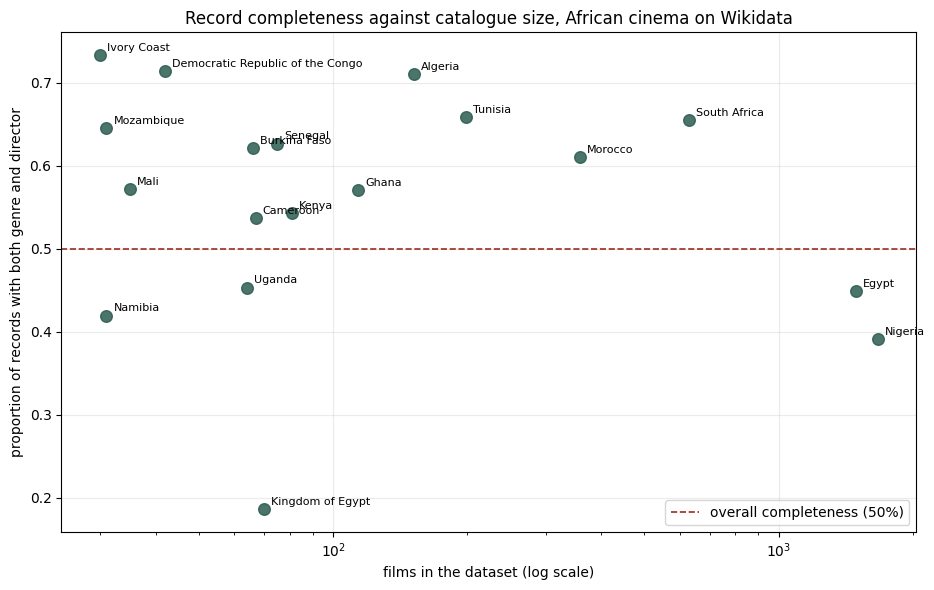

In [15]:
fig, ax = plt.subplots(figsize=(9.5, 6))
ax.scatter(by_country["films"], by_country["completeness"], s=70,
           color="#2b5c50", alpha=.85, zorder=3)
for name, r in by_country.iterrows():
    ax.annotate(name, (r["films"], r["completeness"]), fontsize=8,
                xytext=(5, 3), textcoords="offset points")

overall = df["complete"].mean()
ax.axhline(overall, ls="--", color="#9c2c1f", lw=1.2, zorder=2,
           label=f"overall completeness ({overall:.0%})")
ax.set_xscale("log")
ax.set_xlabel("films in the dataset (log scale)")
ax.set_ylabel("proportion of records with both genre and director")
ax.set_title("Record completeness against catalogue size, African cinema on Wikidata")
ax.legend(loc="lower right")
plt.tight_layout()

print(f"CAPTION. Countries with at least {MIN_FILMS} films (n = {len(by_country)} of "
      f"{df['country'].nunique()} countries, {len(sub):,} of {len(df):,} records).")
print("Completeness is the proportion of records naming both a genre and a director.")
print("Dashed line is the overall rate across the unfiltered dataset.")

## Step 7 · The qualitative half

The regression tells you **which** records are thin. It cannot tell you **why**, and
a chapter with only the quantitative half will be sent back.

The method is a small coding exercise, and it is the part that makes this publishable
rather than descriptive. Module 17's protocol applies: two coders, independently, and
report agreement.

In [16]:
# Draw a purposive sample of thin records to code by hand.
thin = df[df["genre"].isna() & df["director"].isna()]
print(f"{len(thin):,} records have neither genre nor director "
      f"({len(thin)/len(df):.0%} of the dataset)\n")

sample = thin.sample(n=20, random_state=7)[["wikidata_id", "title", "country", "year"]]
print("Twenty to code by hand. Open each on Wikidata and read its edit history:\n")
for _, r in sample.iterrows():
    yr = "" if pd.isna(r["year"]) else int(r["year"])
    print(f"   https://www.wikidata.org/wiki/{r['wikidata_id']:<10}  "
          f"{str(r['title'])[:40]:<42}{r['country']:<16}{yr}")

1,129 records have neither genre nor director (20% of the dataset)

Twenty to code by hand. Open each on Wikidata and read its edit history:

   https://www.wikidata.org/wiki/Q108690187  Confession of a Woman                     Egypt           1971
   https://www.wikidata.org/wiki/Q122829870  Season of tears                           Nigeria         1990
   https://www.wikidata.org/wiki/Q124005407  Why live it solo?                         Egypt           2024
   https://www.wikidata.org/wiki/Q122819249  Over her dead body                        Nigeria         1990
   https://www.wikidata.org/wiki/Q122812173  Arin agbami                               Nigeria         1990
   https://www.wikidata.org/wiki/Q122812116  Ayo ayoju                                 Nigeria         1990
   https://www.wikidata.org/wiki/Q122819090  Ebolo                                     Nigeria         1990
   https://www.wikidata.org/wiki/Q122829834  Orisun                                    Nigeria        

### The coding scheme

Apply one label per record. These are a starting point — refine them after coding
ten, which is what a pilot is for.

| Label | Definition |
|---|---|
| `IMPORT` | Created by a bot or bulk import from an external catalogue; the thinness is the import's shape |
| `PLACEHOLDER` | Created by a human as a stub, with an evident intention to return |
| `ASSERTION` | Created by a human to record that the film *exists*, with no sources available to say more |
| `ORPHAN` | No clear provenance; edit history gives no account |

**Two coders, independently, then compute agreement.** A scheme two people cannot
apply consistently is not a finding, it is an opinion — and reviewers check this.

In [17]:
from sklearn.metrics import cohen_kappa_score

# Replace with your real codes after both coders have worked through the twenty.
coder_a = ["IMPORT","IMPORT","ASSERTION","PLACEHOLDER","IMPORT","ORPHAN","IMPORT",
           "ASSERTION","IMPORT","IMPORT","PLACEHOLDER","ASSERTION","IMPORT","ORPHAN",
           "IMPORT","ASSERTION","IMPORT","IMPORT","PLACEHOLDER","IMPORT"]
coder_b = ["IMPORT","IMPORT","ASSERTION","IMPORT","IMPORT","ORPHAN","IMPORT",
           "PLACEHOLDER","IMPORT","IMPORT","PLACEHOLDER","ASSERTION","IMPORT","ASSERTION",
           "IMPORT","ASSERTION","IMPORT","ORPHAN","PLACEHOLDER","IMPORT"]

kappa = cohen_kappa_score(coder_a, coder_b)
raw = np.mean([x == y for x, y in zip(coder_a, coder_b)])
print(f"raw agreement {raw:.2f}   Cohen's kappa {kappa:.3f}")
print()
print("Landis & Koch: <0.20 slight, 0.21-0.40 fair, 0.41-0.60 moderate,")
print("0.61-0.80 substantial, >0.80 almost perfect.")
print()
print("Where you disagreed:")
for i, (x, y) in enumerate(zip(coder_a, coder_b)):
    if x != y:
        print(f"   record {i+1}: {x} vs {y}")
print()
print("A systematic disagreement is a problem with the SCHEME, not the coder.")
print("Revise the definition and re-code — that is a round, and rounds get reported.")

raw agreement 0.80   Cohen's kappa 0.680

Landis & Koch: <0.20 slight, 0.21-0.40 fair, 0.41-0.60 moderate,
0.61-0.80 substantial, >0.80 almost perfect.

Where you disagreed:
   record 4: PLACEHOLDER vs IMPORT
   record 8: ASSERTION vs PLACEHOLDER
   record 14: ORPHAN vs ASSERTION
   record 18: IMPORT vs ORPHAN

A systematic disagreement is a problem with the SCHEME, not the coder.
Revise the definition and re-code — that is a round, and rounds get reported.


### Scaling Beyond the 20-Record Pilot

When writing your chapter, you can frame the transition from the 20-record pilot to a larger qualitative phase using these methodological justifications:

* **1. Statistical Representativeness:** A 20-record sample is diagnostic. To estimate the true proportion of categories (e.g., what % of thin records are actually bot `IMPORT`s) with a 10% margin of error and 95% confidence, you need a larger random sample (typically around 90-100 records depending on population size).
* **2. Inter-Coder Reliability (Kappa) Stabilization:** Small samples can skew Cohen's Kappa due to random agreement. Running a larger set (e.g., 50 to 100 records) ensures your Kappa reliability score is stable and statistically defensible to peer reviewers.
* **3. Theoretical Saturation:** You can state that the 20-record pilot served to validate and freeze the taxonomy schema (`IMPORT`, `PLACEHOLDER`, `ASSERTION`, `ORPHAN`). The full analysis can then scale up to a larger pool to confirm that no new categories emerge.

In [18]:
# Code to draw a larger, statistically robust random sample for your main qualitative analysis phase
# Based on the same thin-record pool established earlier
thin_records = df[df["genre"].isna() & df["director"].isna()]

# Let's draw a larger representative sample of 100 records for the full scale-up study
scaled_sample_size = 100
scaled_sample = thin_records.sample(n=scaled_sample_size, random_state=42)[["wikidata_id", "title", "country", "year"]]

print(f"=== SCALED-UP QUALITATIVE SAMPLE ({scaled_sample_size} Records) ===")
print(f"This sample represents {scaled_sample_size / len(thin_records):.2%} of the total {len(thin_records):,} thin records.")
print("First 10 records of the scaled-up sample to inspect:")
display(scaled_sample.head(10))

=== SCALED-UP QUALITATIVE SAMPLE (100 Records) ===
This sample represents 8.86% of the total 1,129 thin records.
First 10 records of the scaled-up sample to inspect:


,wikidata_id,title,country,year
2464,Q124005407,Why live it solo?,Egypt,2024.0
4776,Q59725660,Diary of a Lagos Girl,Nigeria,2016.0
5569,Q99845091,Gbewiri Meta,Nigeria,2016.0
1012,Q113504724,Arinzo,Nigeria,NaN
2200,Q122829604,Venom of justice,Nigeria,1990.0
1930,Q122818988,Day break 2,Nigeria,1998.0
2721,Q130395484,Ocean Driven,South Africa,NaN
2651,Q130317422,Behind the Blue Veil,Mali,NaN
5567,Q99840576,Yeye oge,Nigeria,2016.0
2753,Q130748473,The Hidden One,Egypt,2024.0


## Step 8 · Limits

The last page of the chapter, and the first thing a reviewer reads properly.

**What this analysis supports**

- Statements about *this export* of Wikidata, retrieved on its stated date.
- Statements about record completeness as defined here — genre and director both
  present. Another definition gives another number.
- A relationship between country, catalogue size and completeness, with the effect
  sizes reported above.

**What it does not support**

- Any claim about African film *production*. This is a catalogue, not a filmography.
- Any claim about women directors. The variable does not exist in this table.
- Any claim that a country's cinema is under-documented *because* of anything —
  the regression shows association, and the coding exercise offers a mechanism for
  thin records, not a cause for country differences.
- Any claim about Wikidata in general. African cinema is one corner of it.

**YOUR DECISION.** Add two more sentences this data does not support. Being able to
name them is what separates the chapter from a report — and reviewers who see a
short limits section assume you did not look.

---

# Step 9 · The chapter template

You have run the analysis. Now you have to write it, and a chapter is not a
notebook with prose around it — it has a shape, and readers expect that shape.

Below is the structure of a DH book chapter, with **where each thing you computed
belongs**. Fill the gaps. The sentence frames are there to be used and then
rewritten in your own voice once you can see the argument.

**Length.** A DH chapter is usually 6,000–8,000 words. The proportions below are a
guide, not a rule.

---

## §1 Introduction — *about 800 words*

Three jobs, in order: the problem, your claim, why it matters.

> Wikidata is increasingly treated as infrastructure for ______________ .
> This chapter examines ______________ , and argues that ______________ .
> Drawing on a dataset of **_____ films across _____ countries**, it shows that
> ______________ . The finding matters because ______________ .

**Say your claim in the first 200 words.** Humanities training often teaches you to
build to a conclusion. Chapter readers scan; if they cannot find your claim on page
one they stop.

*Feeds in from:* nothing yet — write this **last**, once you know what you found.

---

## §2 The standard and its critics — *about 1,200 words*

Not a general literature review. A specific account of **the metadata standard you
are examining** and the argument you are joining.

> Wikidata records films through properties including ______________ .
> Scholars have argued that ______________ (cite), while others hold that
> ______________ (cite). This chapter contributes ______________ .

Name the property numbers. `P170`, `P21`, `P136` are precise; "Wikidata's metadata"
is not, and reviewers notice.

*Feeds in from:* your reading, not the notebook.

---

## §3 Data — *about 900 words*

Where it came from, what one row is, and what it does not contain.

> The dataset comprises **_____ records**, retrieved on ______________ .
> Each row represents ______________ . Records carry ______________ ,
> and do **not** carry ______________ .

Then the absence audit, which is an argument and not an apology:

> Three absences shape what can be asked. First, ______________ .
> Second, ______________ . Third, ______________ .
> The most consequential for this chapter is ______________ , because
> ______________ .

*Feeds in from:* **Step 2**, the absence audit cell. Use its actual numbers.

---

## §4 Method — *about 700 words*

Enough that someone else could redo it. Past tense, no code.

> Records were classified as complete where both ______________ and
> ______________ were present. Countries with fewer than **_____ records** were
> excluded, retaining **_____ countries** and **_____ records**; this threshold was
> set because ______________ .
> Association between ______________ and ______________ was tested with
> ______________ , reporting ______________ alongside significance.
> Two models were fitted: ______________ and ______________ .

**Report the collinearity problem here**, in one sentence. It shows you understood
your own model rather than accepting whatever converged:

> Catalogue size could not be included alongside country indicators, because
> ______________ .

*Feeds in from:* **Steps 4, 5** — your `MIN_FILMS`, the test, both models.

---

## §5 Findings — *about 1,800 words. The core.*

One finding per subsection, each opening with the claim and then the evidence.
Never open with the method.

**§5.1 ______________**

> Completeness across the dataset is **_____%**. Records from ______________ are
> **_____ percentage points** ______________ than ______________
> (χ² = _____, p _____, φ = _____).

**§5.2 ______________**

> Holding period constant, ______________ ( β = _____, p = _____, odds ratio
> = _____ ). ______ of ______ country effects reach conventional significance.

**§5.3 ______________** *(the qualitative half)*

> Twenty thin records were coded independently by two coders (κ = _____).
> ______________ of them were ______________ , indicating ______________ .

**Where the figure goes.** After the paragraph it supports, never before. Caption
below, and the caption must say what you filtered:

> **Figure 1.** Record completeness against catalogue size, countries with at least
> _____ films (n = _____ of _____ countries; _____ of _____ records). Completeness
> is the proportion of records naming both genre and director. Dashed line: overall
> rate across the unfiltered dataset.

*Feeds in from:* **Steps 3–7**, and the chart from Step 6.

---

## §6 Discussion — *about 1,400 words*

What the finding **means**. This is where a chapter earns its place over a report.

> These results suggest that ______________ . This is consistent with
> ______________ , and complicates ______________ .
> If ______________ , then ______________ .

Then the counter-practice — required, and the thing that turns critique into
contribution:

> Efforts such as ______________ address this by ______________ .
> Their limits are ______________ .

*Feeds in from:* your reading plus the coding scheme's mechanism.

---

## §7 Limitations — *about 500 words*

Specific, not ritual. Name sentences your data does not support.

> This analysis speaks to ______________ and not to ______________ .
> It cannot support claims about ______________ , because ______________ .
> Nor can it support ______________ .
> A different definition of completeness would ______________ .

*Feeds in from:* **Step 8**. Reviewers read this first; a vague limitations section
reads as not having looked.

---

## §8 Conclusion — *about 400 words*

Restate the claim, name what changes because of it, and stop. No new evidence.

---

## §9 References · §10 Data and code availability

> The dataset is available at ______________ . Analysis code is available at
> ______________ . Figures were produced with ______________ .

Depositing the notebook with a DOI (Zenodo, OSF) is increasingly expected and takes
twenty minutes.

In [19]:
# Your own numbers, dropped into the frames above. Copy the output into your
# draft and then rewrite it in your own voice — this is scaffolding, not prose.

overall = df["complete"].mean()
diff_pp = (a.mean() - b.mean()) * 100
n_sig = int((res["p"] < 0.05).sum())
b_coef = fit_b.params["log_size"]; b_p = fit_b.pvalues["log_size"]

print("=" * 72)
print("DRAFT SENTENCES — with your numbers already in place")
print("=" * 72)

print("""
§3 DATA
  The dataset comprises {n:,} records of African films held in Wikidata, covering
  {c} countries and the years {y0}-{y1}. Each row represents one film. Genre is
  absent for {g:.0%} of records and director for {d:.0%}; {both:,} records ({bp:.0%})
  carry neither. No field records the gender of a director, although Wikidata can
  express this through property P21 for the {dirs:,} named directors in the set.
""".format(n=len(df), c=df["country"].nunique(), y0=int(df["year"].min()),
           y1=int(df["year"].max()), g=df["genre"].isna().mean(),
           d=df["director"].isna().mean(),
           both=int((df["genre"].isna() & df["director"].isna()).sum()),
           bp=(df["genre"].isna() & df["director"].isna()).mean(),
           dirs=df["director"].nunique()))

print("""§4 METHOD
  A record was classified as complete where both a genre and a director were
  present. Countries with fewer than {m} records were excluded, retaining {k}
  countries and {s:,} of {n:,} records. Association between country group and
  completeness was tested by chi-square, reporting phi as an effect size. Two
  logistic models were fitted: one with country indicators and period, one with
  catalogue size and period. Catalogue size could not be entered alongside country
  indicators, since it is constant within country and therefore an exact linear
  combination of them.
""".format(m=MIN_FILMS, k=len(keep), s=len(sub), n=len(df)))

print("""§5 FINDINGS
  Completeness across the dataset is {o:.1%}. Records from {bigs} are {dpp:+.1f}
  percentage points less complete than those from other retained countries
  (chi-square = {chi:.1f}, p < 0.001, phi = {phi:.3f}).

  Holding period constant, catalogue size predicts incompleteness: each unit
  increase in log catalogue size is associated with a coefficient of {bc:.3f}
  (p < 0.001, odds ratio {bor:.2f}). {ns} of {nt} country effects reach p < 0.05.
  The direction is the finding: countries with MORE films on Wikidata have LESS
  complete records, which is the signature of bulk import rather than of curation.

  Twenty thin records were coded independently by two coders (kappa = {k:.3f}).
""".format(o=overall, bigs=" and ".join(big), dpp=diff_pp, chi=chi2, phi=phi,
           bc=b_coef, bor=np.exp(b_coef), ns=n_sig, nt=len(res), k=kappa))

print("""FIGURE 1 CAPTION
  Record completeness against catalogue size, countries with at least {m} films
  (n = {k} of {c} countries; {s:,} of {n:,} records). Completeness is the proportion
  of records naming both a genre and a director. Dashed line: overall rate across
  the unfiltered dataset.
""".format(m=MIN_FILMS, k=len(by_country), c=df["country"].nunique(),
           s=len(sub), n=len(df)))
print("=" * 72)
print("Blanks left for you: what it MEANS (S6), what it cannot support (S7),")
print("and the counter-practice. No cell can fill those.")

DRAFT SENTENCES — with your numbers already in place

§3 DATA
  The dataset comprises 5,581 records of African films held in Wikidata, covering
  65 countries and the years 1905-2026. Each row represents one film. Genre is
  absent for 42% of records and director for 28%; 1,129 records (20%)
  carry neither. No field records the gender of a director, although Wikidata can
  express this through property P21 for the 1,867 named directors in the set.

§4 METHOD
  A record was classified as complete where both a genre and a director were
  present. Countries with fewer than 30 records were excluded, retaining 18
  countries and 5,206 of 5,581 records. Association between country group and
  completeness was tested by chi-square, reporting phi as an effect size. Two
  logistic models were fitted: one with country indicators and period, one with
  catalogue size and period. Catalogue size could not be entered alongside country
  indicators, since it is constant within country and therefore 

### Three mistakes that sink first chapters

**Writing the introduction first.** You cannot introduce an argument you have not
found yet. Draft §5 first, then §6, then come back and write §1 last.

**Method in the findings section.** "We then ran a chi-square test and found..."
belongs in §4. §5 opens with the claim: "Records from the two largest producers are
markedly less complete."

**A limitations section that protects you rather than informing the reader.**
"Further research is needed" says nothing. "This dataset cannot support claims about
women directors, because the variable does not exist in it" is precise, and it earns
trust for everything else you wrote.

### On using the generated draft

The cell above writes correct sentences. They are **not yet your prose** — they are
placement practice, showing you which number belongs in which section. Rewrite each
one. A chapter that reads like generated output will be treated as one.

---

# Step 10 · Dividing the work

You are more than five people writing one chapter. That is an advantage, but only if
you divide by **expertise** rather than by paragraph count. A chapter written by six
people each contributing a bit of everything reads like six people, and reviewers say
so.

Digital humanities work is interdisciplinary in a specific sense: it needs someone who
knows the archive, someone who knows the statistics, someone who knows the theory, and
someone who can make the three of them agree. Below is how that maps onto this chapter.

## The roles

| # | Role | Owns | Expertise it draws on | Hands over |
|---|---|---|---|---|
| 1 | **Corpus &amp; provenance** | §3 Data, absence audit | Library and archival science, source criticism | A described dataset and a defended list of absences |
| 2 | **Analysis** | §4 Method, §5.1–5.2 | Statistics, computation | Coefficients, effect sizes, and the reason for every threshold |
| 3 | **Coder A** | §5.3, jointly | Close reading, content analysis | 20 independently assigned codes |
| 4 | **Coder B** | §5.3, jointly | Close reading, content analysis | 20 independently assigned codes |
| 5 | **Theory &amp; literature** | §2, §6 Discussion | Your critical lens; the counter-practice | The argument the chapter is joining |
| 6 | **Visualisation &amp; communication** | Figure 1, captions, §8 | Design, editing | A figure that carries the claim unaided |
| 7 | **Integration editor** | §1, §7, references, §10 | Editorial judgement | One voice, and a chapter that ends |

Seven slots. With six people, roles 6 and 7 combine. With eight, split role 5 —
literature and discussion are genuinely different jobs.

## Why coders 3 and 4 are two people, not one

This is the part that is a **method requirement, not a staffing convenience**.

Cohen's kappa measures whether two readers applying the same scheme independently
reach the same judgement. If one person codes all twenty records, there is no kappa,
no agreement figure, and §5.3 has no evidential standing — it becomes one reader's
impression.

So: coders 3 and 4 must **not** discuss the records while coding. Agree the scheme,
separate, code, then compare. The disagreements are data, and they usually point at a
definition that needs sharpening rather than a coder who needs correcting.

## The order things have to happen in

Roles are not simultaneous. This is the dependency chain:

```
   Corpus & provenance  ──┐
                          ├──►  Analysis  ──►  Visualisation  ──┐
   Coders A + B  ─────────┘                                     ├──►  Integration
                                                                │
   Theory & literature  ────────────────────────────────────────┘
```

Two consequences worth planning around:

- **Theory can start on day one.** It does not wait for results, and the group that
  leaves the literature until the numbers are in will run out of time.
- **Integration cannot start until everything else exists**, and needs real time. The
  introduction is written last, because you cannot introduce a finding you do not yet
  have.

## Combining the drafts

Six documents stapled together is not a chapter. Two rules make integration work:

**One person edits for voice, and everyone accepts the edit.** Not by vote. The
integration editor's job is consistency of tense, terminology and register — if §3
says "records" and §5 says "entries", a reader assumes carelessness.

**Agree the terms in advance, in writing.** Before drafting, fix: what you call the
unit (record? entry? item?), what "complete" means, and how you refer to the standard.
Ten minutes at the start saves a day at the end.

## Declaring who did what

Journals and edited collections increasingly ask for this, and the standard vocabulary
is **CRediT** (Contributor Roles Taxonomy — conceptualisation, data curation, formal
analysis, investigation, methodology, software, visualisation, writing – original
draft, writing – review and editing).

Declaring contributions is not bureaucracy. In interdisciplinary work it is how a
statistician and a historian each get credited for the thing they actually did, and it
protects the person whose contribution is least visible in the prose.

In [20]:
# A contribution statement to fill in and paste at the end of your chapter.
TEAM = {
    "Corpus & provenance":       ("________________", "data curation, investigation"),
    "Analysis":                  ("________________", "formal analysis, software, methodology"),
    "Coder A":                   ("________________", "investigation, validation"),
    "Coder B":                   ("________________", "investigation, validation"),
    "Theory & literature":       ("________________", "conceptualisation, writing - original draft"),
    "Visualisation & comms":     ("________________", "visualisation, writing - review and editing"),
    "Integration editor":        ("________________", "writing - review and editing, supervision"),
}
print("AUTHOR CONTRIBUTIONS (CRediT)\n")
for role, (name, credit) in TEAM.items():
    print(f"  {name}: {credit}.")
    print(f"      [{role}]")
print()
print("Fill in the names, delete the bracketed role labels, and put this after the")
print("conclusion. Order the names as your group agrees — and agree it EARLY, because")
print("authorship order is the argument that ruins collaborations when left late.")

AUTHOR CONTRIBUTIONS (CRediT)

  ________________: data curation, investigation.
      [Corpus & provenance]
  ________________: formal analysis, software, methodology.
      [Analysis]
  ________________: investigation, validation.
      [Coder A]
  ________________: investigation, validation.
      [Coder B]
  ________________: conceptualisation, writing - original draft.
      [Theory & literature]
  ________________: visualisation, writing - review and editing.
      [Visualisation & comms]
  ________________: writing - review and editing, supervision.
      [Integration editor]

Fill in the names, delete the bracketed role labels, and put this after the
conclusion. Order the names as your group agrees — and agree it EARLY, because
authorship order is the argument that ruins collaborations when left late.


### Methodology Calculations
This cell computes the exact numbers needed for your **§4 Method** section based on the `MIN_FILMS = 30` decision.

In [21]:
min_films_threshold = 30
counts = df['country'].value_counts()
retained_countries = counts[counts >= min_films_threshold]
excluded_countries_count = len(counts) - len(retained_countries)
total_records = len(df)
retained_records = len(df[df['country'].isin(retained_countries.index)])
excluded_records = total_records - retained_records

print("=== METHODOLOGY DRAFT NUMBERS ===")
print(f"1. Minimum films threshold: {min_films_threshold}")
print(f"2. Retained countries: {len(retained_countries)} out of {df['country'].nunique()}")
print(f"3. Excluded countries: {excluded_countries_count}")
print(f"4. Retained records: {retained_records:,} ({retained_records/total_records:.1%})")
print(f"5. Excluded thin-catalogue records: {excluded_records:,} ({excluded_records/total_records:.1%})")


=== METHODOLOGY DRAFT NUMBERS ===
1. Minimum films threshold: 30
2. Retained countries: 18 out of 65
3. Excluded countries: 47
4. Retained records: 5,206 (93.3%)
5. Excluded thin-catalogue records: 375 (6.7%)


### What goes wrong, and how to see it coming

**Everyone waits for the analysis.** Roles 1 and 5 can work from day one. If four
people are idle while one person fits a model, the division of labour has failed.

**The coders talk.** Understandable and fatal — it destroys the independence that
makes kappa mean anything. If it happens, say so in the methods section rather than
reporting a figure you know is inflated.

**Nobody owns the ending.** Chapters written by committee tend to stop rather than
conclude. Role 7 owns §8, and owns the decision that the draft is finished.

**The specialist writes only their section.** The statistician should read §6, and the
theorist should read §5. Interdisciplinary work fails at the seams, and the seams are
exactly where nobody has been asked to look.

## What to hand in

1. **One page**: the finding, the method, the uncertainty, and the list above.
2. **One chart**, captioned, saying what you filtered.
3. **The coding sheet** with both coders' labels and the kappa.

### Turning this into the chapter

The draft has a spine already: a measured pattern, a mechanism from the coding, and
a structural absence (gender) that is representable and unrepresented. What it still
needs from you is the **counter-practice** — someone, somewhere, is fixing this.
Language-community edit-a-thons, WikiProject Africa, AfroCROWD. A critique with no
counter-practice reads as a complaint; with one, it reads as an intervention.